# Pod 7: how wide is it?

This is a **notebook**: cells of code and cells of text, with the output of each code cell kept under it. Run a cell with Shift+Return. The first cell checks that the notebook is using the course's Python; it must print a path containing `astr119`. If it does not, click the kernel name at the top right and pick `astr119`.

Before every code cell: write your prediction on the pod sheet, then run, then compare.

In [1]:
import sys
print(sys.executable)   # must contain 'astr119'

/opt/miniconda3/envs/astr119/bin/python


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
rng = np.random.default_rng(1)     # seeded: the whole room gets the same numbers

## Task 0: the notebook itself

A notebook is made of **cells**. A few things to know before you use one (from the course's 2024 notes):

- Each cell is either **code** (Python) or **text** (Markdown, like this one). Select a cell and press `Y` for code, `M` for text; double-click a text cell to edit it.
- **Shift+Return** runs the selected cell (a text cell too: it renders) and moves to the next one. Printed output and figures appear **under** the cell.
- You can insert, delete, move, copy and split cells (the toolbar above, or `A` / `B` to add a cell above / below the selected one, `D D` to delete it).
- **Keep cells small.** A few lines each. Not too much.
- A variable defined in one cell is available to every cell you run **afterwards**, whatever the order on the page. That is convenient, and it is the classic trap: before you trust a notebook, **Restart** and **Run All** and read from the top.

*A word of caution.* Notebooks are tempting, and they bring problems as code grows: think of one as a messy lab notebook for trying ideas. When you are ready for the final version, consolidate into a stand-alone, well-commented `.py` file.

**Do this now:** add a text cell below this one (press Esc, then `B`, then `M`) and type your pod's names in it. Then add a code cell under that and run `print(2 + 2)`. Tick 0.1 on the sheet when both have output.

Hamilton Johnson, Yahir Paniagua, Vera Scovil

In [3]:
print(2 + 2)

4


## Task 1: a histogram is a picture of a pile of numbers

Ten thousand measurements of something whose true value is 100, each off by a random error of typical size 15.

In [4]:
# 1.1  Ten thousand numbers. Predict the mean and the standard deviation before you run.
x = rng.normal(100, 15, 10000)
print(x.mean(), x.std())
print(x.min(), x.max())

99.83630648318731 14.977440444448172
42.43206785923154 158.97666820566482


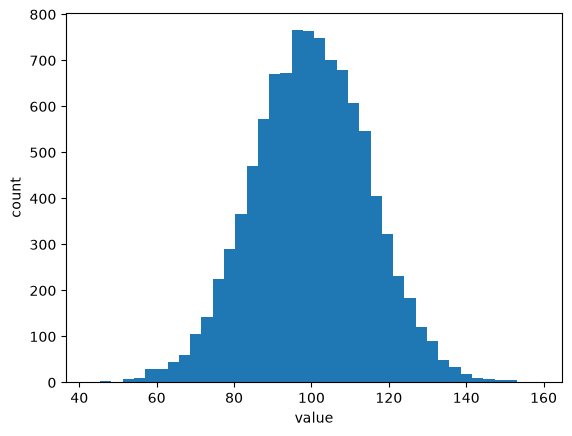

In [ ]:
# 1.2  The histogram. Before you run: what is on the x axis, what is on the y axis, where is the peak, how tall is the tallest bar?
fig, ax = plt.subplots()
ax.hist(x, bins=40)
ax.set_xlabel("value")
ax.set_ylabel("count")
fig.savefig("normal.png")    # the notebook runs in its own folder, so the file lands here in module-4/

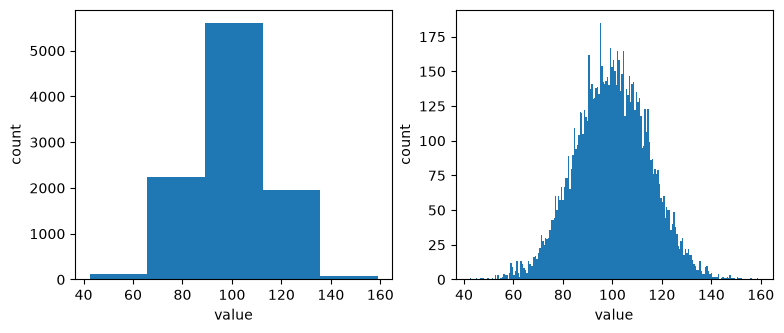

In [6]:
# 1.3  The same numbers, 5 bins and 200 bins. Predict what changes and what does not.
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.5))
a1.hist(x, bins=5)
a2.hist(x, bins=200)
for a in (a1, a2):
    a.set_xlabel("value")
    a.set_ylabel("count")
fig.savefig("normal_bins.png")

In [7]:
# 1.4  Fewer measurements. Predict: which sample gives a mean closest to 100 and a std closest to 15?
for n in (10, 100, 1000, 10000):
    s = rng.normal(100, 15, n)
    print(n, round(s.mean(), 1), round(s.std(), 1))

10 93.4 17.5
100 100.9 14.6
1000 99.4 14.8
10000 99.9 14.8


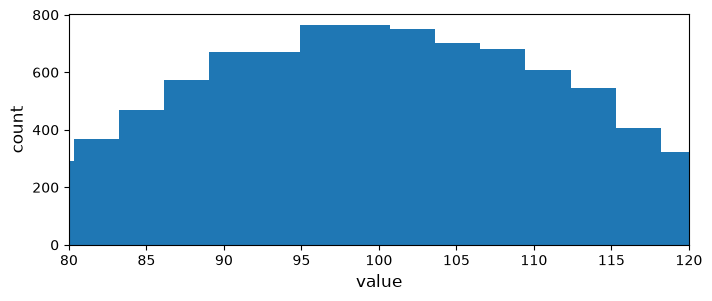

In [11]:
# 1.5  Size and zoom. Predict: what does set_xlim(80, 120) do to the picture, and what happens to the bars outside it?
fig, ax = plt.subplots(figsize=(8, 3))     # width, height in inches
ax.hist(x, bins=40)
ax.set_xlim(80, 120)                       # show only this range of values
ax.set_xlabel("value", fontsize=12)
ax.set_ylabel("count", fontsize=12)
fig.savefig("normal_zoom.png")

## Task 2: how wide is it? Three ways

The width of the pile is the thing a scientist usually wants: it is the size of the measurement error. Measure it three ways and compare.

0.687


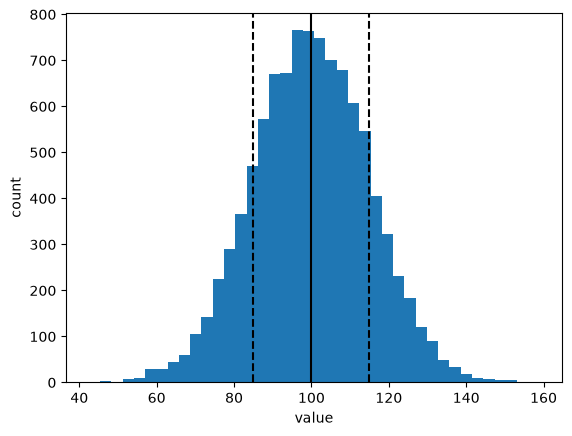

In [12]:
# 2.1  Way one: the standard deviation, and what it means. Predict the fraction of the numbers within one std of the mean.
m = abs(x - x.mean()) < x.std()        # a mask: True for the numbers within one std
print(m.mean())                         # the fraction

fig, ax = plt.subplots()
ax.hist(x, bins=40)
ax.axvline(x.mean(), color="k")
ax.axvline(x.mean() - x.std(), color="k", linestyle="--")
ax.axvline(x.mean() + x.std(), color="k", linestyle="--")
ax.set_xlabel("value")
ax.set_ylabel("count")
fig.savefig("normal_marked.png")

In [13]:
# 2.2  Way two: by eye. The full width at half maximum (FWHM): how far apart are the two places where the
#      histogram has fallen to half its peak? For a bell curve, FWHM = 2.35 * std.
counts, edges = np.histogram(x, bins=40)      # the bars as numbers: counts, and the bin edges
centers = 0.5 * (edges[:-1] + edges[1:])      # the middle of each bin
half = counts.max() / 2
print("tallest bar:", counts.max(), "  half of it:", half)
for c, n in zip(centers, counts):
    if n >= half:
        print(round(c, 1), n)                 # the bins that reach at least half the peak: read the first and the last
# On the sheet: FWHM by eye = last - first.  Divide by 2.35: is it near 15?

tallest bar: 765   half of it: 382.5
84.7 470
87.6 572
90.5 671
93.4 672
96.3 765
99.2 764
102.2 749
105.1 701
108.0 680
110.9 607
113.8 547
116.7 405


In [ ]:
# 2.3  Way three: fit a bell curve. curve_fit adjusts height, center and width until the curve matches the bars.
#      It needs a starting guess p0. Take it from what you saw: height ~ the tallest bar, center ~ the peak, width ~ FWHM / 2.35.
def gauss(v, height, center, width):
    return height * np.exp(-(v - center)**2 / (2 * width**2))

p0 = [700, 100, 10]                           # replace with YOUR three guesses from 1.2 and 2.2 before you run
best, cov = curve_fit(gauss, centers, counts, p0=p0)
errors = np.sqrt(np.diag(cov))
print("height, center, width:", best.round(2))
print("uncertainties:        ", errors.round(2))

fig, ax = plt.subplots()
ax.hist(x, bins=40, label="10,000 numbers")
v = np.linspace(40, 160, 300)
ax.plot(v, gauss(v, *best), "k-", label="bell-curve fit")
ax.set_xlabel("value")
ax.set_ylabel("count")
ax.legend()
fig.savefig("normal_fit.png")

In [ ]:
# 2.4  What if the starting guess is far off? Predict: does the fit still find the same answer?
bad, cov_bad = curve_fit(gauss, centers, counts, p0=[1, 1, 1])
print(bad.round(2))

## Task 3: make it yours

Pick one as a pod, or combine, or invent something. Each of you in your own notebook. Predict before each run; write what you did on the sheet.

- **Uniform beside normal.** `u = rng.random(10000)`: its histogram next to the normal one in two panels. Mean and std of `u`? Does a bell curve fit it?
- **Two populations.** Add `rng.normal(150, 5, 2000)` to `x` with `np.concatenate` and histogram the lot. What does a single bell-curve fit do with it?
- **Few measurements.** Fit the histogram of only 100 numbers. How big are the uncertainties now?
- **The moon picture.** Histogram of the red values of `clean_io_small.png` (it is in `../module-3/`). Is it a bell curve at all?
- **A combination, or something else** that makes a histogram and says how wide it is.

In [ ]:
# Task 3: your code here


Before you upload: **Restart** the kernel and **Run All**, and check that every cell runs top to bottom. Then upload this notebook, with its outputs, and the photo of the sheet.